# Treino do detector de frutas e maturação

Este notebook treina um **YOLO11 nano** para encontrar **banana, laranja e tomate**
e dizer o estágio de maturação de cada fruta (**verde, amadurecendo, maduro, passado**).
No fim, ele gera o arquivo `frutas_yolo11n.onnx`, que a app usa na VPS sem GPU.

**Antes de rodar**

1. *Ambiente de execução > Alterar o tipo de ambiente de execução* > **GPU T4**.
2. Crie uma conta gratuita no [Roboflow](https://app.roboflow.com) e copie a chave da API
   (*Settings > API Keys*).
3. No Colab, abra o ícone de chave (**Secrets**) na barra lateral, crie o segredo
   `ROBOFLOW_API_KEY` com a chave e ative o acesso para este notebook.
4. *Ambiente de execução > Executar tudo*. Autorize o acesso ao Google Drive quando pedir: o
   treino é salvo lá e, se o Colab desconectar, basta executar tudo de novo que ele continua de
   onde parou.

O treino completo leva cerca de 1 a 2 horas na T4, dependendo do tamanho dos datasets.

**Depois:** baixe `frutas_yolo11n.onnx` (a última célula oferece o download) e coloque o
arquivo em `models/` no repositório. A app passa a usar o modelo treinado sozinha.

In [1]:
import os

# Teste rápido fora do Colab (dados sintéticos e CPU). Deixe False no Colab.
SMOKE_TEST = os.getenv("SMOKE_TEST") == "1"

EPOCHS = 2 if SMOKE_TEST else 100   # o treino para antes se parar de melhorar (PATIENCE)
PATIENCE = 20
IMGSZ = 320 if SMOKE_TEST else 640
BATCH = 4 if SMOKE_TEST else 16
BASE_MODEL = "yolo11n.pt"           # nano: o único que roda bem na VPS de 1 vCPU
SAVE_TO_DRIVE = True                # salva o treino no Google Drive: sobrevive a desconexões do Colab

In [2]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !nvidia-smi -L
    !pip install -q ultralytics roboflow onnx onnxslim
    if not Path("/content/fruits_analyzer").exists():
        !git clone -q https://github.com/omneto/fruits_analyzer.git /content/fruits_analyzer
    %cd /content/fruits_analyzer
    !git pull -q

sys.path.insert(0, str(Path.cwd()))
from training.datasets import CLASS_NAMES, DEFAULT_SOURCES, download_roboflow, merge_datasets, read_class_names, stats_table

WORK_DIR = Path("/content/work") if IN_COLAB else Path("work")
# Pasta dos resultados do treino. No Drive, ela sobrevive se o Colab desconectar.
RUNS = (WORK_DIR / "runs").resolve()  # caminho absoluto: a Ultralytics muda caminhos relativos
if IN_COLAB and SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RUNS = Path("/content/drive/MyDrive/fruits_analyzer/runs")
RUNS.mkdir(parents=True, exist_ok=True)
print("Resultados do treino em:", RUNS)
print("Classes do modelo:", CLASS_NAMES)

GPU 0: Tesla T4 (UUID: GPU-64669b21-4720-afae-429f-5a147ae10be5)
/content/fruits_analyzer
Mounted at /content/drive
Resultados do treino em: /content/drive/MyDrive/fruits_analyzer/runs
Classes do modelo: ['banana_verde', 'banana_amadurecendo', 'banana_maduro', 'banana_passado', 'laranja_verde', 'laranja_amadurecendo', 'laranja_maduro', 'laranja_passado', 'tomate_verde', 'tomate_amadurecendo', 'tomate_maduro', 'tomate_passado']


## 1. Datasets

Os datasets padrão são públicos no Roboflow Universe (licença CC BY 4.0). Cada um tem nomes de
classe próprios, que são convertidos para o padrão do projeto (`banana_maduro`, `tomate_verde`...).
O mapeamento fica em `training/datasets.py`.

Para trocar ou acrescentar um dataset, edite a lista abaixo. Classes fora do `class_map` são
deduzidas pelo nome (`unripe` → verde, `rotten` → passado...) ou descartadas.

In [3]:
from training.datasets import DatasetSource

SOURCES = list(DEFAULT_SOURCES)

# Exemplo para acrescentar outro dataset de banana:
# SOURCES.append(DatasetSource(
#     name="banana2", fruit="banana",
#     roboflow_workspace="<workspace>", roboflow_project="<projeto>",
#     class_map={"green": "verde", "yellow": "maduro", "brown": "passado"},
# ))

for s in SOURCES:
    print(f"{s.fruit:8} {s.url}  ({s.license})")

banana   https://universe.roboflow.com/fruit-ripening/banana-ripening-process  (CC BY 4.0)
laranja  https://universe.roboflow.com/yashas/orange_ripeness  (CC BY 4.0)
tomate   https://universe.roboflow.com/tomatoes-dectection-riped/tomatoes-growth-by-laboro  (CC BY 4.0 (derivado do Laboro Tomato))


In [4]:
RAW_DIR = WORK_DIR / "raw"
downloaded = []
if SMOKE_TEST:
    from training.synthetic import make_synthetic_sources
    downloaded = make_synthetic_sources(RAW_DIR)
else:
    from google.colab import userdata
    api_key = userdata.get("ROBOFLOW_API_KEY")
    for src in SOURCES:
        path = download_roboflow(src, api_key, RAW_DIR)
        downloaded.append((src, path))

for src, path in downloaded:
    print(f"{src.name}: classes originais = {read_class_names(path)}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/raw/banana in yolov11:: 100%|██████████| 36160/36160 [00:07<00:00, 5041.56it/s]


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/raw/laranja in yolov11:: 100%|██████████| 2502/2502 [00:00<00:00, 8439.35it/s]


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/work/raw/tomate in yolov11:: 100%|██████████| 2429/2429 [00:00<00:00, 10091.13it/s]

banana: classes originais = ['freshripe', 'freshunripe', 'overripe', 'ripe', 'rotten', 'unripe']
laranja: classes originais = ['ripe_orange', 'unripe_orange']
tomate: classes originais = ['b_fully_ripened', 'b_green', 'b_half_ripened', 'l_fully_ripened', 'l_green', 'l_half_ripened']


In [5]:
stats = merge_datasets(downloaded, WORK_DIR / "merged")
print(stats_table(stats))

classe                   train     val    test
----------------------------------------------
banana_verde              4086     417     212
banana_amadurecendo       4197     408     174
banana_maduro            10272     969     507
banana_passado           13002    1218     626
laranja_verde              611      44       0
laranja_amadurecendo         0       0       0
laranja_maduro             555      48       0
laranja_passado              0       0       0
tomate_verde              7802    1398     559
tomate_amadurecendo       1944     367     177
tomate_maduro             1949     369     195
tomate_passado               0       0       0
imagens: {'test': 838, 'train': 17922, 'val': 1775}


Confira a tabela: classes com poucas caixas (menos de ~100) terão resultado fraco.
A laranja, por exemplo, só tem "verde" e "maduro" no dataset padrão.

## 2. Treino

In [6]:
from ultralytics import YOLO

LAST = RUNS / "frutas" / "weights" / "last.pt"
if LAST.exists() and not SMOKE_TEST:
    # Um treino anterior foi interrompido (ex.: o Colab desconectou): continua de onde parou.
    print("Retomando o treino de", LAST)
    model = YOLO(str(LAST))
    model.train(resume=True)
else:
    model = YOLO(BASE_MODEL)
    model.train(
        data=stats["data_yaml"],
        epochs=EPOCHS,
        patience=PATIENCE,
        imgsz=IMGSZ,
        batch=BATCH,
        project=str(RUNS),
        name="frutas",
        exist_ok=True,
        workers=0 if SMOKE_TEST else 2,
        plots=not SMOKE_TEST,
    )
BEST = Path(model.trainer.best)
print("Melhor modelo:", BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Retomando o treino de /content/drive/MyDrive/fruits_analyzer/runs/frutas/weights/last.pt
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/merged/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10

## 3. Avaliação

In [7]:
best = YOLO(str(BEST))
metrics = best.val(data=stats["data_yaml"], imgsz=IMGSZ, batch=BATCH, plots=not SMOKE_TEST, workers=0, project=str(RUNS), name="val", exist_ok=True)
print(f"mAP50 geral: {metrics.box.map50:.3f}   mAP50-95: {metrics.box.map:.3f}")
for i, cls_id in enumerate(metrics.box.ap_class_index):
    print(f"  {CLASS_NAMES[int(cls_id)]:<22} mAP50 = {metrics.box.ap50[i]:.3f}")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,724 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 809.3±627.7 MB/s, size: 23.4 KB)
val: Scanning /content/work/merged/val/labels.cache... 1775 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1775/1775 437.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 111/111 5.4it/s 20.7s
                   all       1775       5238      0.877      0.845      0.905      0.728
          banana_verde        185        417      0.853      0.885      0.938      0.696
   banana_amadurecendo        161        408      0.831      0.838      0.911      0.611
         banana_maduro        612        969        0.9      0.939      0.976      0.755
        banana_passado        724       1218      0.912      0.875      0.949       0.66
         laranja_verde         44    

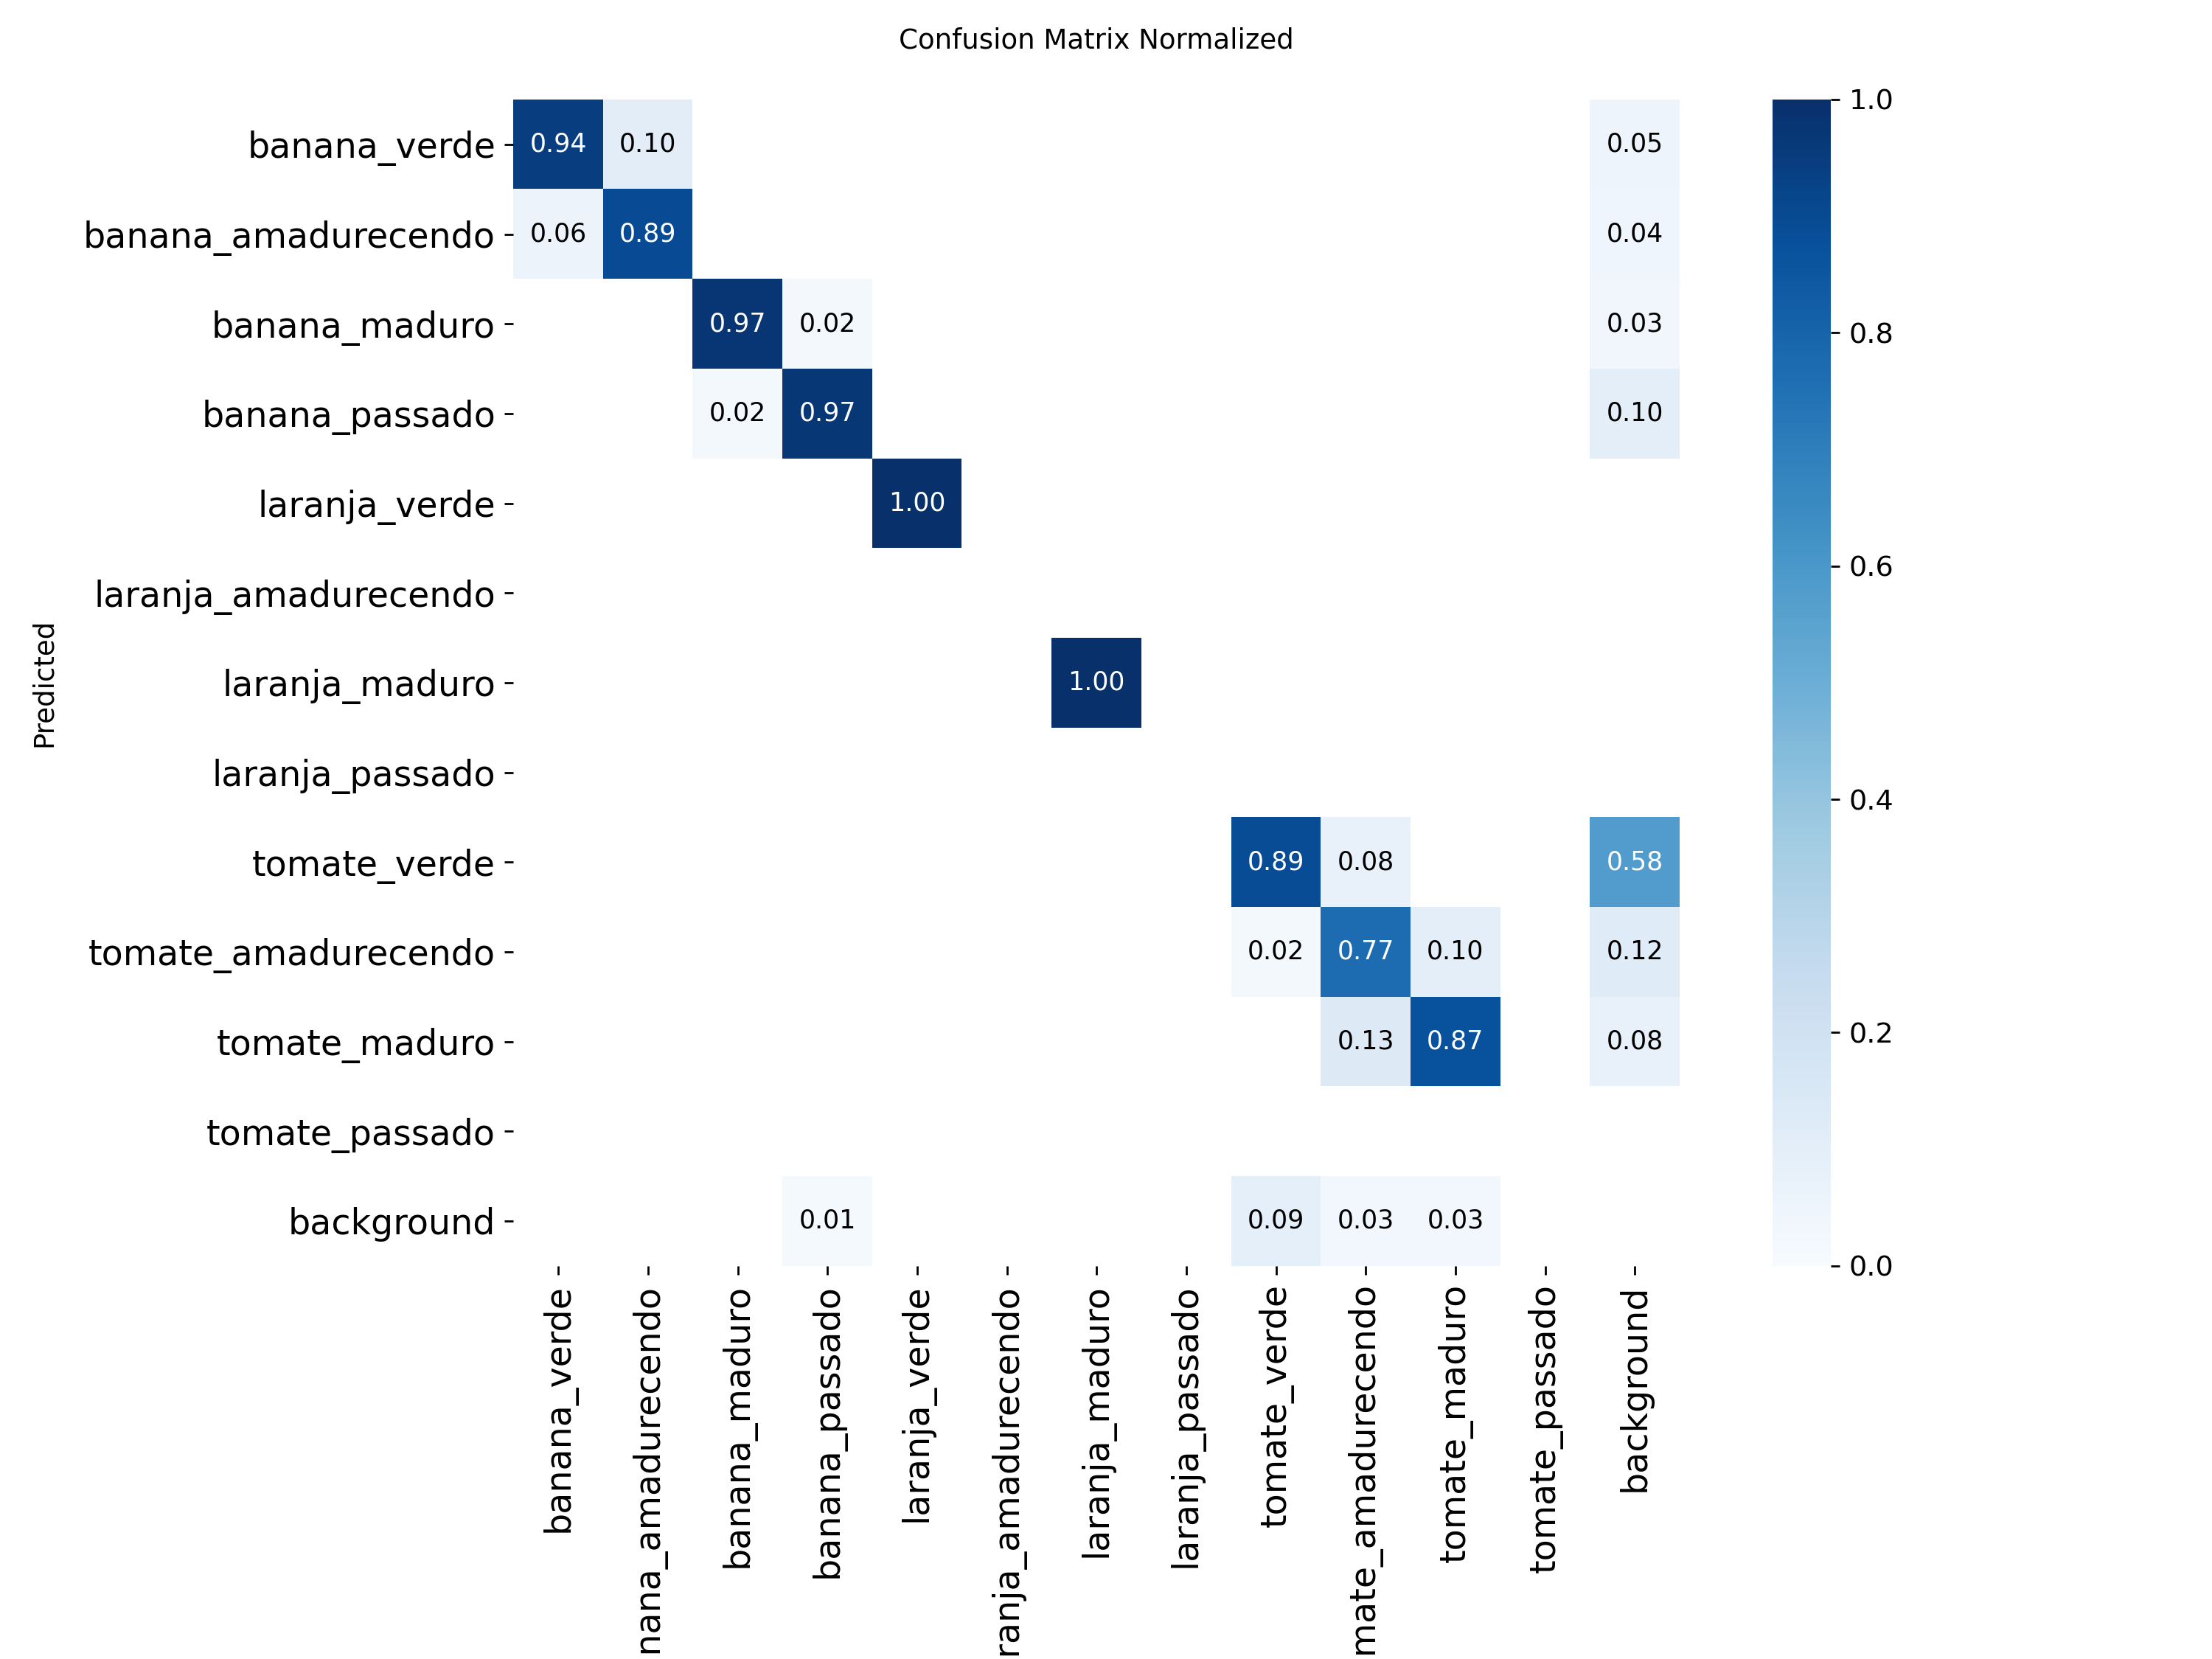

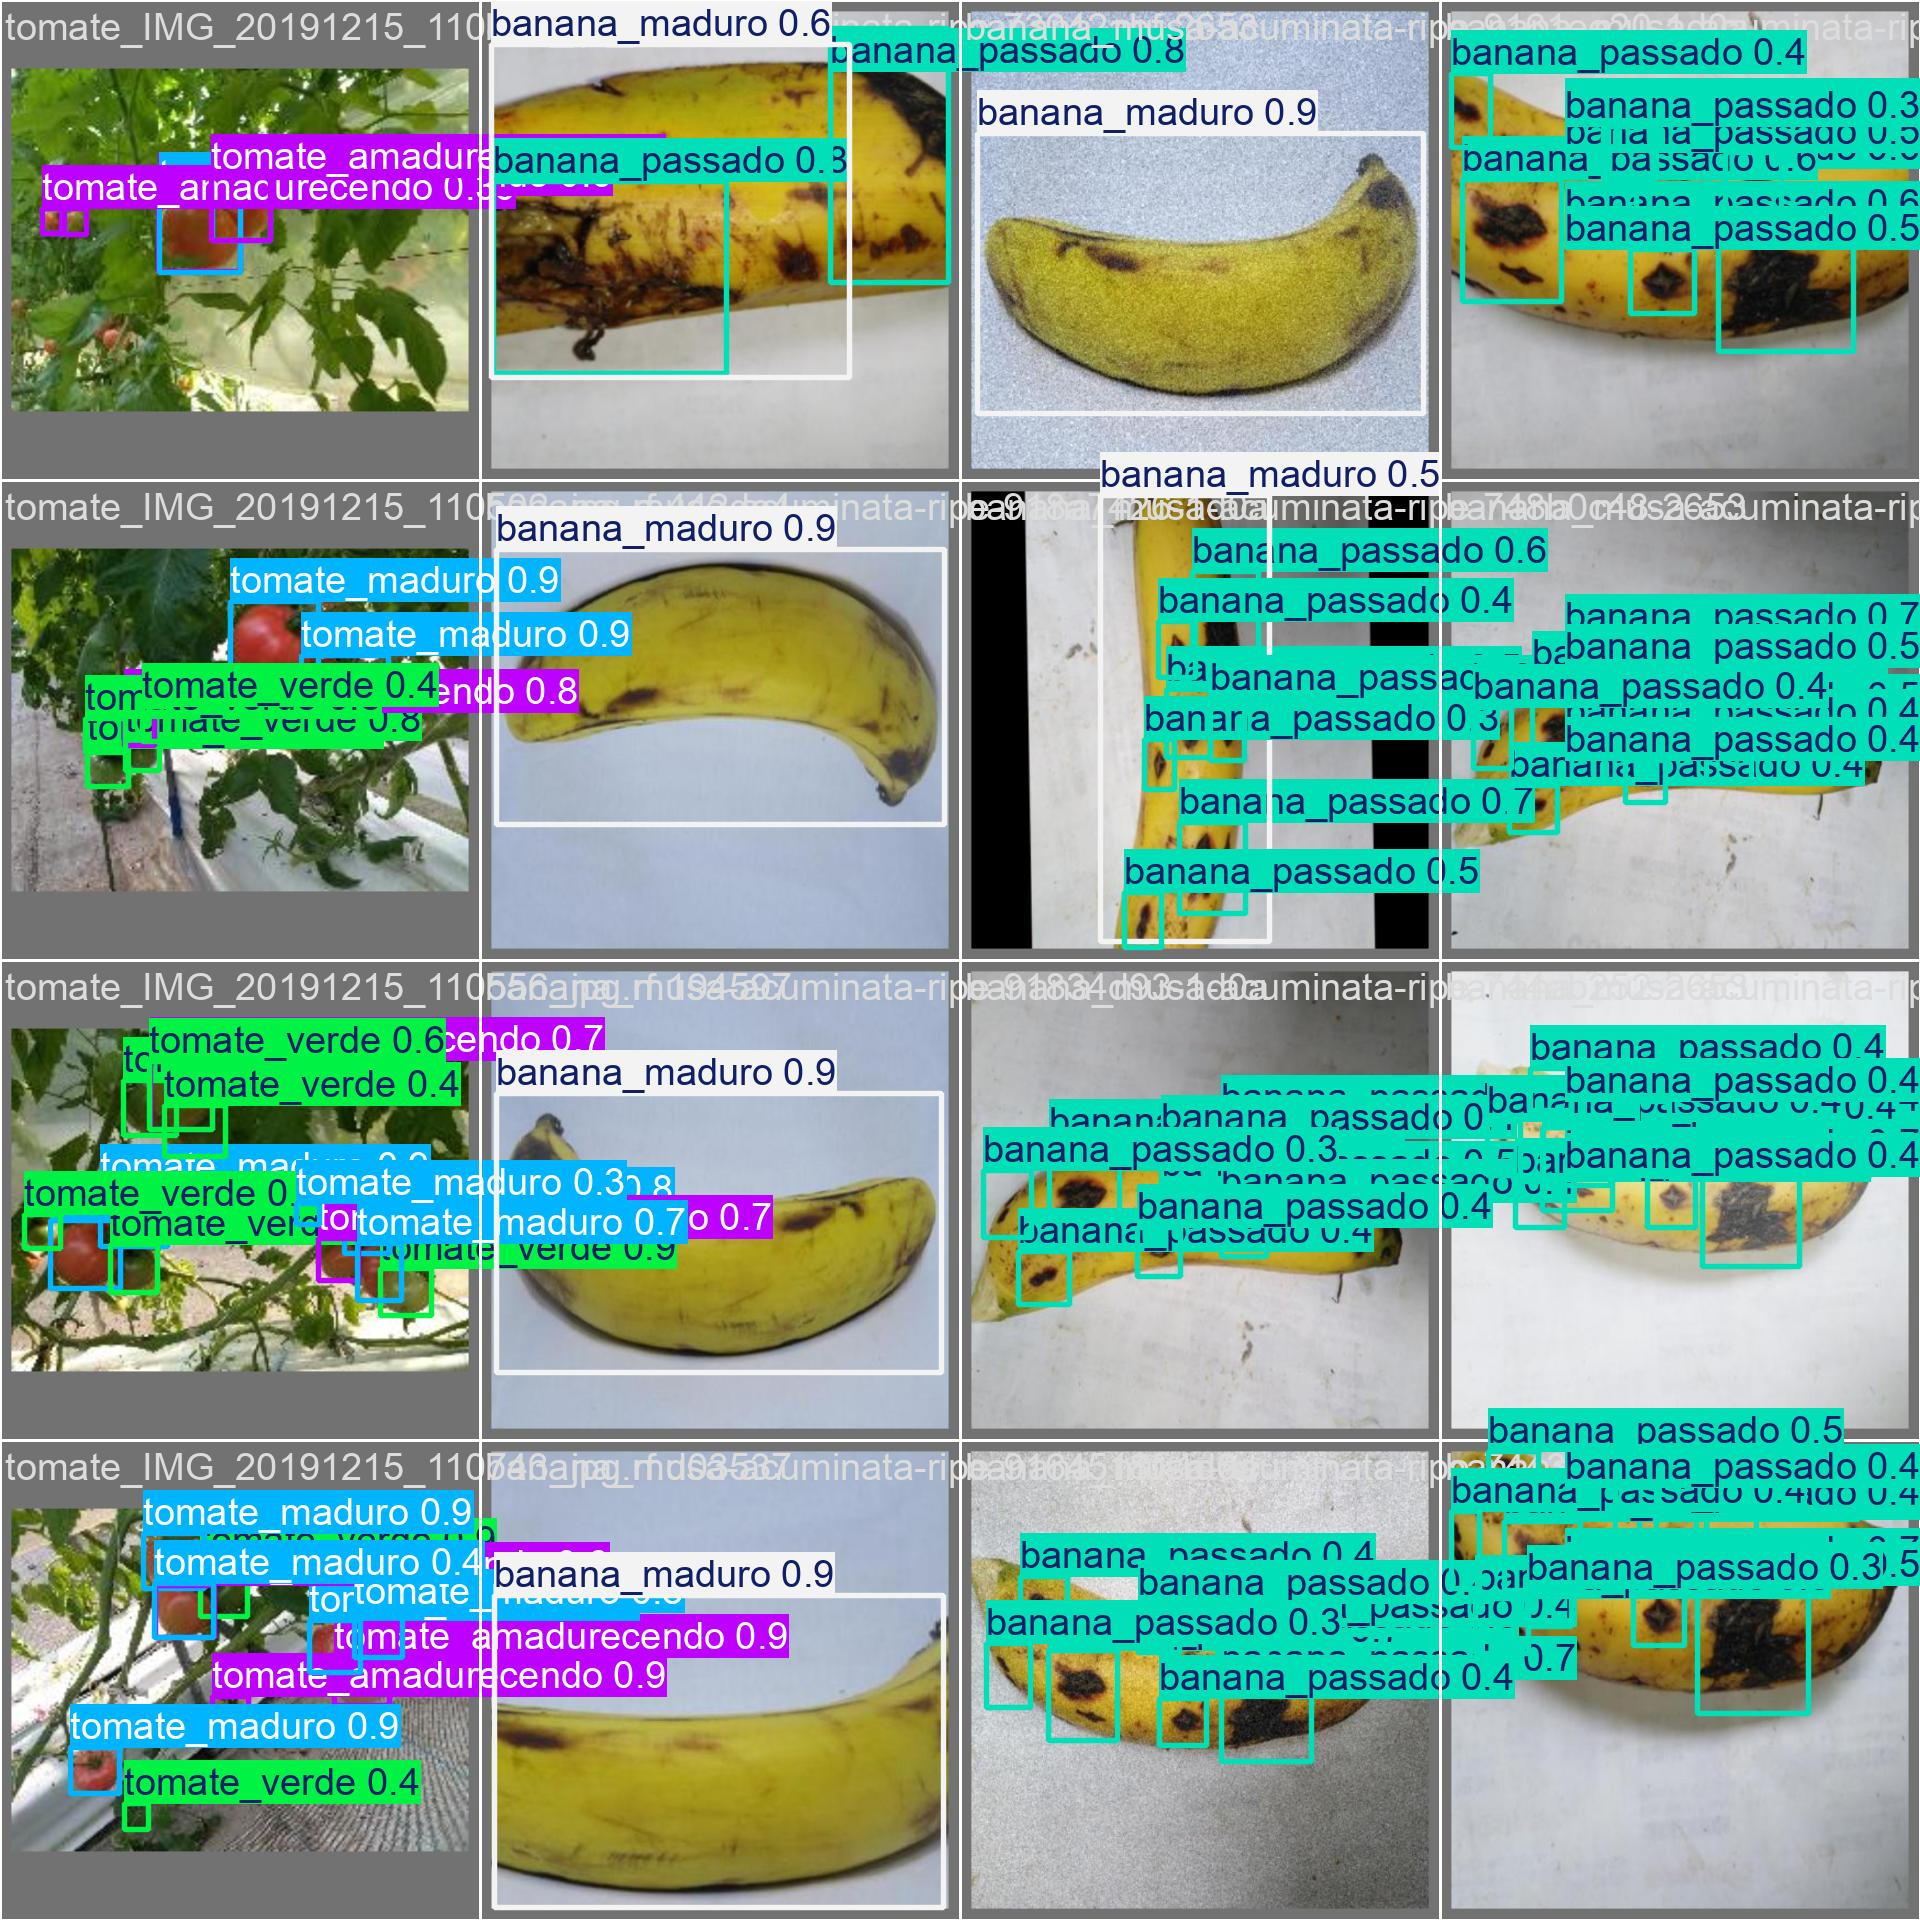

In [8]:
from IPython.display import Image as ShowImage, display

for name in ["confusion_matrix_normalized.png", "val_batch0_pred.jpg"]:
    for found in RUNS.glob(f"**/{name}"):
        display(ShowImage(filename=str(found), width=900))
        break

## 4. Exportar para ONNX (para a VPS)

In [9]:
import shutil
from pathlib import Path

import onnx
from ultralytics import YOLO

# Funciona mesmo depois de reiniciar a sessão: procura o best.pt salvo em disco.
if "best" not in globals():
    places = [Path("/content/drive/MyDrive/fruits_analyzer/runs"), Path("/content/work/runs"), Path("work/runs")]
    found = [p / "frutas/weights/best.pt" for p in places if (p / "frutas/weights/best.pt").exists()]
    if not found:
        raise FileNotFoundError("Nenhum best.pt encontrado: rode o treino (seção 2) antes de exportar.")
    BEST = found[-1]
    print("Usando", BEST)
    best = YOLO(str(BEST))
IMGSZ = globals().get("IMGSZ", 640)

onnx_path = best.export(format="onnx", imgsz=IMGSZ, simplify=True, opset=17)
MODEL_OUT = Path("models/frutas_yolo11n.onnx")
MODEL_OUT.parent.mkdir(exist_ok=True)
shutil.copy(onnx_path, MODEL_OUT)

# Confere as classes gravadas no arquivo (só com o pacote onnx, sem onnxruntime).
meta = {p.key: p.value for p in onnx.load(str(MODEL_OUT)).metadata_props}
print("Classes gravadas no modelo:", meta.get("names"))
print(f"Arquivo: {MODEL_OUT} ({MODEL_OUT.stat().st_size / 1e6:.1f} MB)")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,599,724 parameters, 0 gradients, 6.5 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/fruits_analyzer/runs/frutas/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 16, 8400) (5.3 MB)
requirements: Ultralytics requirement ['onnxruntime'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 303ms
Prepared 1 package in 766ms
Installed 1 package in 11ms
 + onnxruntime==1.32.0

requirements: AutoUpdate success ✅ 1.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 4.2s, saved as '/content/drive/My

In [10]:
import sys

if "google.colab" in sys.modules:
    from google.colab import files
    drive_dir = Path("/content/drive/MyDrive/fruits_analyzer")
    if drive_dir.exists():
        shutil.copy(MODEL_OUT, drive_dir)
        print("Cópia salva no Drive:", drive_dir / MODEL_OUT.name)
    files.download(str(MODEL_OUT))

Cópia salva no Drive: /content/drive/MyDrive/fruits_analyzer/frutas_yolo11n.onnx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Próximo passo

Coloque `frutas_yolo11n.onnx` em `models/` no repositório e rode `docker compose up -d --build`
na VPS. A app detecta o modelo treinado, libera o tomate e passa a mostrar
"Maturação (modelo treinado)". Para voltar ao modelo antigo, apague o arquivo ou defina
`MODEL_PATH=/app/models/coco_yolo11n.onnx`.

O `best.pt` fica no Drive em `fruits_analyzer/runs/frutas/weights/`. Ele permite continuar o treino depois com
mais fotos, inclusive fotos suas anotadas no Roboflow.